# So sánh ngân sách tìm kiếm và ảnh hưởng khởi tạo TPE

Phần mở rộng nghiên cứu Random Search, TPE startup 5 và TPE startup 10 trên
5 search seeds. Mỗi phương pháp dùng 30 trials mỗi seed, tổng 450 trials.
Notebook đọc logs đã lưu, không tự chạy lại HPO.

Các thí nghiệm này chỉ sử dụng development. Kết quả test, lựa chọn mô hình
và model của thí nghiệm ban đầu được giữ nguyên. Không dùng bảng test cũ để
chọn cấu hình, epsilon hoặc phương pháp cho phần mở rộng.


In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd().resolve()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
if not (ROOT / 'src').exists():
    raise RuntimeError('Open the notebook inside the project folder.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
OUTPUT = ROOT / 'results/robustness'
FIGURES = ROOT / 'figures/robustness'
if not (OUTPUT / 'budget_summary.csv').exists():
    raise RuntimeError('Run python run_robustness.py first, using a fresh output folder if needed.')
manifest = json.loads((OUTPUT / 'run_manifest.json').read_text(encoding='utf-8'))
assert manifest['status'] == 'completed'
assert manifest['test_evaluations'] == 0
print('Search seeds:', manifest['plan']['search_seeds'])
print('Completed trials:', manifest['completed_trials'])
print('Additional test evaluations:', manifest['test_evaluations'])
print('Actual runtime seconds:', round(manifest['runtime_seconds'], 2))
display(pd.Series(manifest['versions'], name='Installed version'))

Search seeds: [11, 22, 33, 44, 55]
Completed trials: 450
Additional test evaluations: 0
Actual runtime seconds: 1205.62


numpy            2.2.2
pandas           2.2.3
scikit-learn     1.8.0
optuna           5.0.0
matplotlib      3.10.0
joblib           1.5.3
Name: Installed version, dtype: object

## Thiết kế thực nghiệm có kiểm soát

Giữ nguyên development 1.437 mẫu, ba folds đã lưu, miền 560 cấu hình,
Macro-F1 và RF seed 123. Chỉ số startup của TPE là yếu tố thay đổi trong
ablation. Random Search làm mốc so sánh. TPE startup 5 dùng 5 trials đầu lấy
mẫu ngẫu nhiên, TPE startup 10 dùng 10 trials đầu lấy mẫu ngẫu nhiên.

Tất cả studies chạy mới trong cùng phiên, tuần tự, n_jobs=1, không pruning.
Thứ tự ba phương pháp xoay vòng theo seed. Không ghép thời gian từ lần chạy
ngày trước. Phần mở rộng chỉ thực hiện CV, không refit để đo model size/latency,
nên thời gian này không so trực tiếp với tổng thời gian pipeline ban đầu.

Mean và SD mô tả biến thiên qua search seeds trên cùng dữ liệu và folds.
Chúng không phải confidence interval hoặc bằng chứng tổng quát cho dataset khác.


In [2]:
display(pd.DataFrame(manifest['schedule']))
print('Original protocol fingerprint:', manifest['base_config_sha256'])
print('Study plan fingerprint:', manifest['plan_sha256'])
trials = pd.read_csv(OUTPUT / 'trials.csv')
display(trials.groupby(['method','seed']).agg(trials=('trial','count'), best_cv_f1=('cv_f1','max')))

,seed,method,startup
0,11,random,NaN
1,11,tpe_startup_5,5.0
2,11,tpe_startup_10,10.0
3,22,tpe_startup_5,5.0
4,22,tpe_startup_10,10.0
5,22,random,NaN
6,33,tpe_startup_10,10.0
7,33,random,NaN
8,33,tpe_startup_5,5.0
9,44,random,NaN


Original protocol fingerprint: ef06bf172c1ce37d3cdfedd2f2fd1fb761bb6dd4bf09117394bcde87d5f268ec
Study plan fingerprint: 05be2380eaa70b63df954c28a67e6b684eb047db660670ec0c80886f39f152b5


trials  best_cv_f1
method         seed                    
random         11        30    0.973429
               22        30    0.974848
               33        30    0.971929
               44        30    0.972064
               55        30    0.969276
tpe_startup_10 11        30    0.969129
               22        30    0.974142
               33        30    0.973352
               44        30    0.974142
               55        30    0.973352
tpe_startup_5  11        30    0.974848
               22        30    0.974142
               33        30    0.974848
               44        30    0.974142
               55        30    0.974142

## Chất lượng theo ngân sách số trials

Mỗi checkpoint chỉ xét các trials đã hoàn tất trong prefix 10, 20 hoặc 30.
Không lấy cấu hình tốt của trial 30 để báo kết quả cho ngân sách 10. Phần
startup cũng tính trong 30 trials. Đường thể hiện điểm tốt nhất đã quan sát,
dải màu là một độ lệch chuẩn qua năm search seeds.


,method,budget,best_cv_f1_mean,best_cv_f1_std,elapsed_seconds_mean,elapsed_seconds_std,elapsed_seconds_median,cv_seconds_mean,unique_configs_mean,seeds
0,random,10,0.967506,0.001567,13.741985,3.952954,11.737142,13.649139,9.6,5
1,random,20,0.971175,0.002534,32.315187,17.940819,26.408427,32.116792,19.4,5
2,random,30,0.972309,0.002068,53.718365,41.339858,35.446790,53.416293,28.6,5
3,tpe_startup_10,10,0.967506,0.001567,13.557562,4.289674,11.279045,13.452524,9.6,5
4,tpe_startup_10,20,0.972281,0.002230,27.546833,18.080069,20.720094,27.305930,18.2,5
5,tpe_startup_10,30,0.972824,0.002103,138.270735,200.840881,28.311244,137.848702,26.4,5
6,tpe_startup_5,10,0.971594,0.003754,11.811883,4.639406,10.669762,11.730140,9.4,5
7,tpe_startup_5,20,0.973846,0.000828,28.124911,18.208010,21.350171,27.883582,18.2,5
8,tpe_startup_5,30,0.974425,0.000387,48.904706,39.840957,33.274046,48.475427,26.6,5


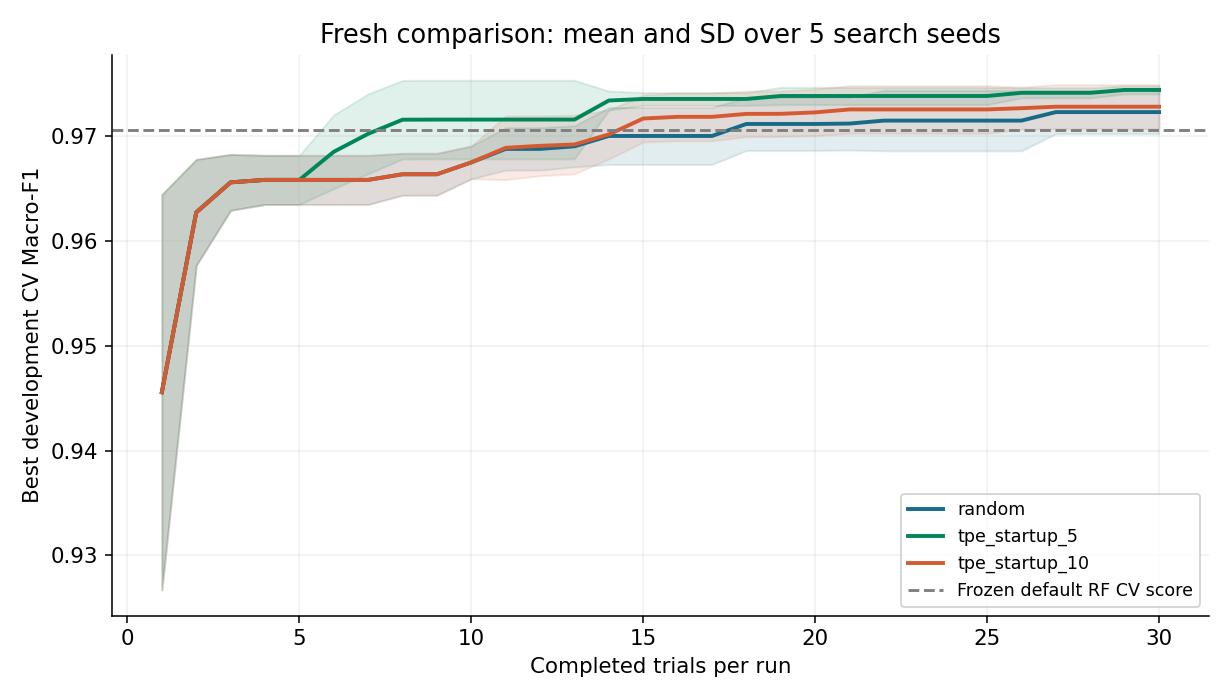

Highest mean development CV score at the full budget: tpe_startup_5
This does not change the previously published deployment model.


In [3]:
budget = pd.read_csv(OUTPUT / 'budget_summary.csv')
display(budget)
display(Image(filename=str(FIGURES / 'search_budget.png')))
last = budget[budget.budget == manifest['plan']['trials_per_method']].sort_values('best_cv_f1_mean', ascending=False)
print('Highest mean development CV score at the full budget:', last.iloc[0]['method'])
print('This does not change the previously published deployment model.')

## Chất lượng theo ngân sách thời gian

Elapsed search time bao gồm gợi ý tham số, CV, bookkeeping và overhead ghi log
trước đó. Đồng hồ bắt đầu riêng cho từng study. Các phương pháp dùng cùng miền
thời gian: bắt đầu khi mọi run đã hoàn tất ít nhất một trial và kết thúc trước
khi bất kỳ run nào hết ngân sách 30 trials.

Ở mỗi thời điểm, chỉ dùng score của trials đã hoàn tất. Không nội suy điểm,
không điền ngược score trước trial đầu và không kéo dài đường sau khi study kết
thúc. Thời gian vẫn chịu ảnh hưởng của CPU và tải nền trên máy. Bảng bên dưới
giữ lại cả những run chậm. Xem mean, SD và median cùng logs từng seed trước khi
kết luận về tốc độ. Logs không đủ để quy toàn bộ biến động thời gian cho thuật toán.


{'available': True,
 'start_seconds': 3.1190609999466687,
 'stop_seconds': 21.397616099915467,
 'grid_points': 60,
 'policy': 'Common overlap only; no interpolation, backfill, or extrapolation of trial scores.'}

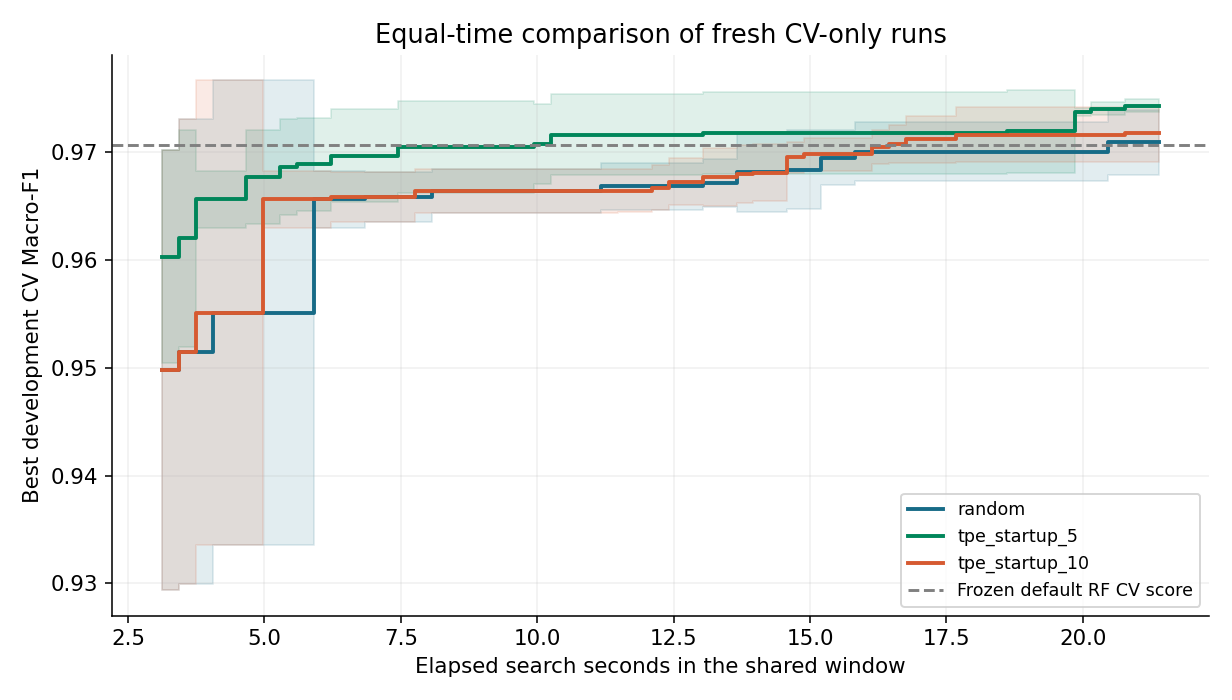

,method,seed,elapsed_seconds,best_cv_f1,completed_trials
298,random,55,21.087810,0.969228,10
299,random,55,21.397616,0.969228,10
598,tpe_startup_10,55,21.087810,0.969228,10
599,tpe_startup_10,55,21.397616,0.969228,10
898,tpe_startup_5,55,21.087810,0.973434,10
899,tpe_startup_5,55,21.397616,0.973434,10


,method,seed,elapsed_seconds,cv_seconds
2,random,11,32.421734,32.352513
5,random,22,32.685468,32.552195
8,random,33,35.446790,35.293216
11,random,44,40.602856,40.423211
14,random,55,127.434978,126.460331
17,tpe_startup_10,11,24.791554,24.656054
20,tpe_startup_10,22,28.311244,28.147774
23,tpe_startup_10,33,27.707227,27.516285
26,tpe_startup_10,44,490.172617,489.892241
29,tpe_startup_10,55,120.371034,119.031157


In [4]:
time_window = json.loads((OUTPUT / 'time_comparison.json').read_text(encoding='utf-8'))
display(time_window)
display(Image(filename=str(FIGURES / 'time_budget.png')))
timed = pd.read_csv(OUTPUT / 'time_budget_per_seed.csv')
if not timed.empty:
    display(timed.groupby('method').tail(2))
cost = pd.read_csv(OUTPUT / 'budget_per_seed.csv')
display(cost[cost.budget == manifest['plan']['trials_per_method']][['method','seed','elapsed_seconds','cv_seconds']])

## Ablation số trials khởi tạo TPE

Ghép TPE startup 5 và startup 10 theo cùng search seed. Delta dương nghĩa là
startup 5 có best CV Macro-F1 cao hơn ở ngân sách 30, delta âm nghĩa là startup
10 cao hơn. Cùng seed không đồng nghĩa hai phương pháp thử toàn bộ cùng cấu
hình sau giai đoạn khởi tạo. Đây là so sánh mô tả, không tuyên bố có ý nghĩa
thống kê từ chỉ năm cặp.


,seed,tpe_startup_10,tpe_startup_5,delta_low_minus_high,winner
0,11,0.969129,0.974848,0.005719,tpe_startup_5
1,22,0.974142,0.974142,0.000000,tie
2,33,0.973352,0.974848,0.001496,tpe_startup_5
3,44,0.974142,0.974142,0.000000,tie
4,55,0.973352,0.974142,0.000790,tpe_startup_5


{'comparison': 'TPE startup 5 minus startup 10',
 'paired_seeds': 5,
 'mean_delta_cv_f1': 0.0016010312320964282,
 'std_delta_cv_f1': 0.0023851457952060733,
 'low_startup_wins': 3,
 'high_startup_wins': 0,
 'ties': 2,
 'interpretation': 'Paired descriptive differences over search seeds, not a significance test or dataset-level confidence interval.'}

Mean paired F1 difference, percentage points: 0.1601


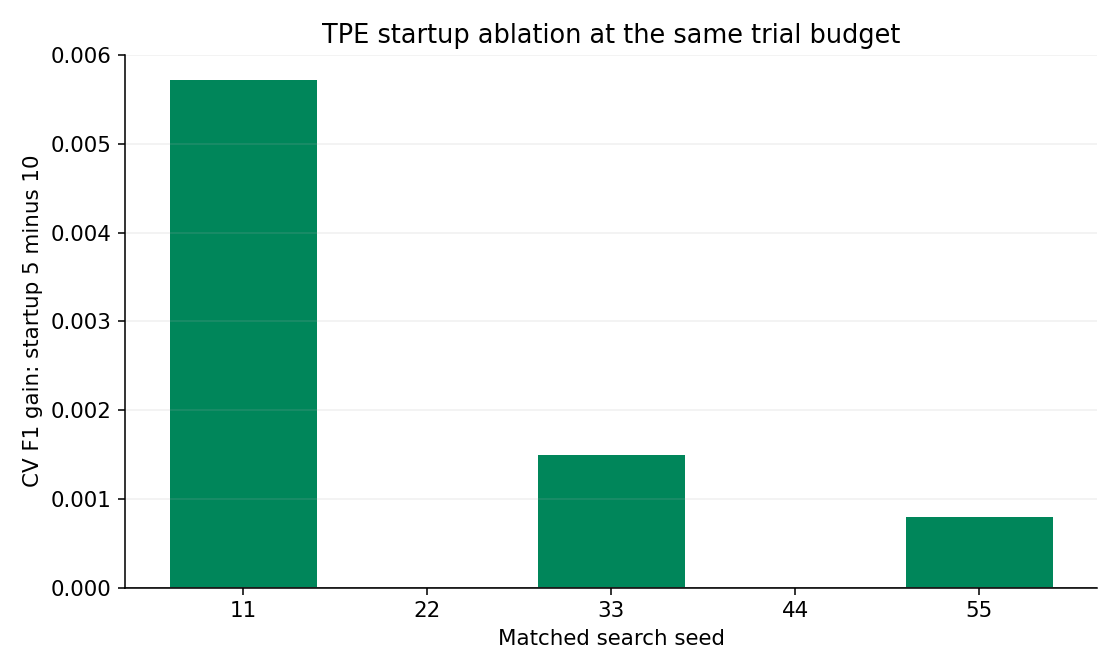

In [5]:
pairs = pd.read_csv(OUTPUT / 'startup_ablation_pairs.csv')
ablation = json.loads((OUTPUT / 'startup_ablation_summary.json').read_text(encoding='utf-8'))
display(pairs)
display(ablation)
print('Mean paired F1 difference, percentage points:', round(100*ablation['mean_delta_cv_f1'], 4))
display(Image(filename=str(FIGURES / 'startup_ablation.png')))

## Kiểm chứng kết quả và bảo toàn thí nghiệm gốc

Các kiểm tra đối chiếu log JSON/CSV, mean và SD, ngân sách mỗi seed, cặp
ablation và các score trong đường thời gian. SHA-256 xác nhận các logs,
predictions, bảng test, selection và model gốc không thay đổi. Văn bản chuẩn
hóa CRLF thành LF để việc checkout Git trên Windows/Linux không tạo báo lỗi giả.
Model nhị phân được kiểm tra chính xác từng byte.


In [6]:
from src.robustness_validation import validate_robustness
checks = validate_robustness(OUTPUT)
print('Passed integrity checks:', len(checks))
print('Preserved original artifacts:', len(manifest['frozen_artifacts']))

C:\Users\lequy\OneDrive\Desktop\Bài Tập Lớn cô Anh\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PASS: 3278 development-study checks; published results preserved.


Passed integrity checks: 3278
Preserved original artifacts: 26


## Chạy lại và giới hạn kết luận

```bash
python run_robustness.py --output results/robustness-reproduction-01
```

Một lần chạy đầy đủ có 450 trials x 3 folds = 1.350 lần fit CV, cộng baseline
3 folds. Dùng thư mục mới, không ghi đè các kết quả đã lưu. Thư mục mặc định
`results/robustness` là bộ kết quả công bố; các lần chạy lại tự đặt figures cạnh
logs của lần chạy đó. Pipeline lưu JSON sau mỗi trial nhưng không hỗ trợ resume.

Kết luận chỉ áp dụng cho dataset, folds, phiên bản thư viện, miền tìm kiếm và
budget hiện tại. Chưa kiểm tra độ nhạy với cách chia dữ liệu hoặc RF seed.
Không dùng thí nghiệm development bổ sung để tuyên bố có kết quả test mới.

Nguồn: https://optuna.readthedocs.io/en/stable/reference/samplers/index.html
và https://docs.github.com/en/actions/tutorials/build-and-test-code/python.
Codex hỗ trợ code và kiểm chứng. Số liệu hiển thị sinh từ logs thực nghiệm thật.
